# 1.3 EDA: spread, skewness and uncertainty through the day

**Question.** How different are households from each other at each half-hour, how lopsided is that spread, and how precisely does SERL pin down the average?

**Data.** The four SERL half-hourly files (2020–2023), whole sample, all days, Wh per half-hour, read with `serl_energy.dataset`.

**Method.** Each SERL row gives, for one group in one half-hour, the mean, median, quartiles, standard deviation and standard error **across households**. From these: coefficient of variation (CV = sd / mean, spread relative to the average), quartile (Bowley) and Pearson skewness, interquartile range, and a 95% confidence interval for the mean. Electricity exports come from very few PV homes after 2021 and are left out of the charts.

**Outputs.** Figures in `reports/figures/1.3-eda-distributions/`, tables in `reports/tables/1.3-eda-distributions/`.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from serl_energy import dataset as serl, plots
from serl_energy.plots import COLORS, INK, SEQUENTIAL_CMAP, YEAR_COLORS
from serl_energy.reporting import Reporter

plots.use_theme()
reporter = Reporter("1.3-eda-distributions")
MAIN = {"Electricity imports": COLORS["electricity"], "Gas": COLORS["gas"]}
YEARS = list(serl.YEARS)


def add_metrics(df: pd.DataFrame) -> pd.DataFrame:
    """Derived statistics for SERL rows (each row = one group, one half-hour, across households)."""
    out = df.copy()
    mean, sd, sem = out["mean"], out["standard_deviation"], out["standard_error_mean"]
    med, q1, q3 = out["median"], out["25th_percentile"], out["75th_percentile"]
    out["cv"] = sd / mean
    out["iqr"] = q3 - q1
    out["pearson_skew"] = 3 * (mean - med) / sd
    out["bowley_skew"] = (q3 + q1 - 2 * med) / (q3 - q1)
    out["ci95_low"] = mean - 1.96 * sem
    out["ci95_high"] = mean + 1.96 * sem
    out["ci_halfwidth_pct"] = 100 * 1.96 * sem / mean
    out["n_from_sem"] = (sd / sem) ** 2           # should match n_rounded: a check on SERL's own numbers
    num = out.select_dtypes("number").columns
    out[num] = out[num].replace([np.inf, -np.inf], np.nan)
    return out


hh = serl.load_half_hourly()
QUANTITIES = ["Electricity imports", "Electricity exports", "Gas"]
base = pd.concat([add_metrics(serl.select_slice(hh, q, "Wh")) for q in QUANTITIES], ignore_index=True)
print(f"{len(base)} rows = {len(QUANTITIES)} quantities x 4 years x 48 half-hours")
check = (base["n_from_sem"] / base["n_rounded"]).describe()
print(f"households implied by sd/SEM vs SERL's n_rounded: median ratio {check['50%']:.3f}")

576 rows = 3 quantities x 4 years x 48 half-hours
households implied by sd/SEM vs SERL's n_rounded: median ratio 1.000


## 1. Summary by quantity and year

Medians over the 48 half-hours; the CI half-width is the 95% margin of error as a percentage of the mean.


In [2]:
summary = (base.groupby(["quantity", "year"])
           .agg(households=("n_rounded", "mean"), kwh_per_day=("mean", lambda m: m.sum() / 1000),
                median_cv=("cv", "median"), median_bowley_skew=("bowley_skew", "median"),
                median_pearson_skew=("pearson_skew", "median"), median_ci_halfwidth_pct=("ci_halfwidth_pct", "median"))
           .reset_index())
summary["households"] = summary["households"].round().astype(int)
print(summary.round(3).to_string(index=False))
reporter.save_table(summary, "distribution_summary_by_year")
reporter.save_table(base[["quantity", "year", "summary_time", "n_rounded", "mean", "median", "25th_percentile",
                          "75th_percentile", "cv", "bowley_skew", "pearson_skew", "ci95_low", "ci95_high"]]
                    .rename(columns={"n_rounded": "households", "mean": "mean_wh", "median": "median_wh",
                                     "25th_percentile": "q1_wh", "75th_percentile": "q3_wh",
                                     "ci95_low": "ci95_low_wh", "ci95_high": "ci95_high_wh"}),
                    "half_hourly_distribution_stats")

           quantity  year  households  kwh_per_day  median_cv  median_bowley_skew  median_pearson_skew  median_ci_halfwidth_pct
Electricity exports  2020        3669        0.218      7.931                 NaN                0.379                   25.659
Electricity exports  2021       10805        0.301      7.731                 NaN                0.393                   14.578
Electricity exports  2022        8229        0.035     19.854                 NaN                0.151                   42.896
Electricity exports  2023        8527        0.014     29.385                 NaN                0.102                   61.939
Electricity imports  2020        3744       11.025      0.835               0.217                0.768                    2.677
Electricity imports  2021       10818       10.083      0.763               0.209                0.750                    1.437
Electricity imports  2022        8750        8.682      0.726               0.189                0.731  

## 2. How different are households at each time of day?

CV for every half-hour and year; darker = households differ more relative to the average. **Look for:** households are most alike in the early evening and least alike overnight, when a minority (storage heaters, EV charging, night tariffs) uses far more than everyone else.


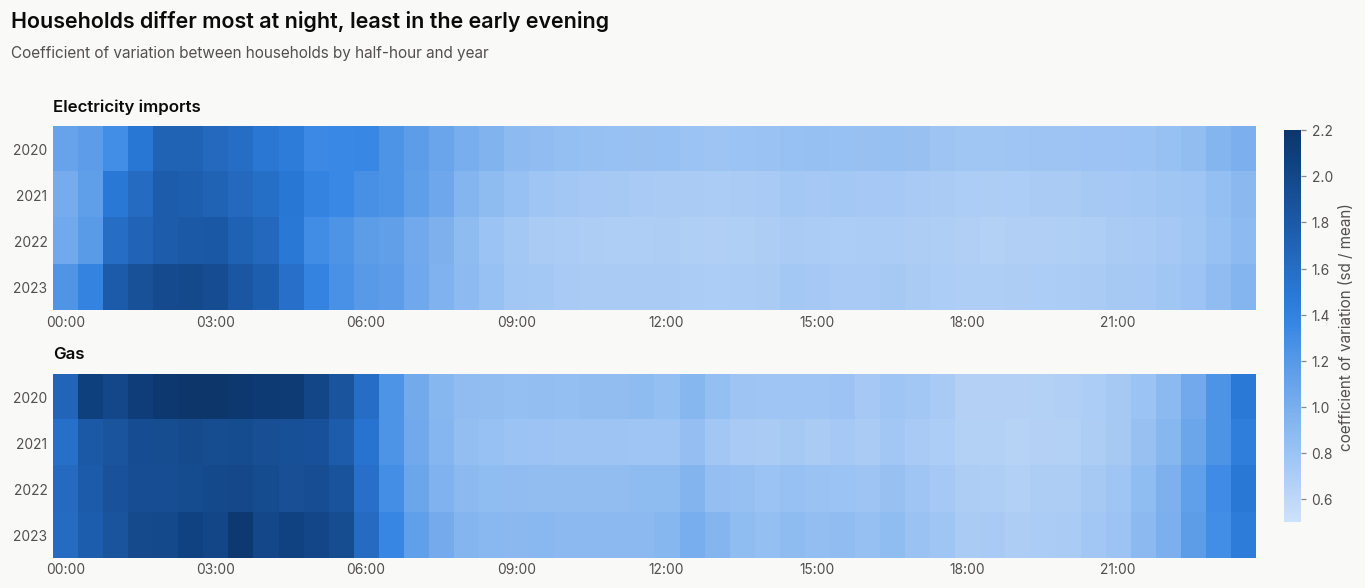

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(13, 5.4))
for ax, q in zip(axes, MAIN):
    grid = base[base["quantity"].eq(q)].pivot(index="year", columns="half_hour", values="cv")
    im = ax.imshow(grid, cmap=SEQUENTIAL_CMAP, aspect="auto", vmin=0.5, vmax=2.2)
    ax.set_yticks(range(len(grid)), grid.index); ax.grid(False); ax.tick_params(length=0)
    plots.half_hour_axis(ax); ax.set_xlim(-0.5, 47.5)
    for side in ("left", "bottom"):
        ax.spines[side].set_visible(False)
    ax.set_title(q, loc="left", fontsize=11)
plots.figure_title(fig, "Households differ most at night, least in the early evening",
                   "Coefficient of variation between households by half-hour and year")
fig.subplots_adjust(right=0.88)
cbar = fig.colorbar(im, cax=fig.add_axes((0.90, 0.12, 0.012, 0.66)))
cbar.set_label("coefficient of variation (sd / mean)"); cbar.outline.set_visible(False)
reporter.save_fig(fig, "cv-heatmap-by-half-hour")
plt.show()

## 3. Is the spread lopsided?

Positive skewness at every half-hour means a long tail of high users: the mean sits above the median, so the median describes a typical household better. Bowley skewness uses only quartiles (robust); Pearson skewness uses mean, median and sd.


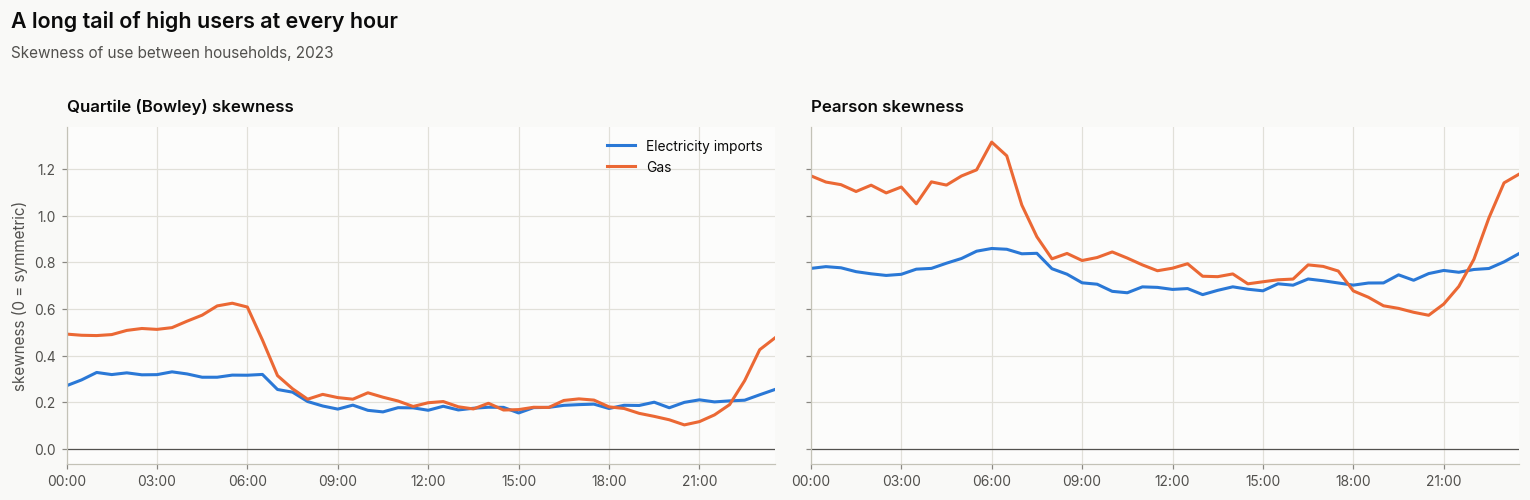

In [4]:
d23 = base[base["year"].eq(2023)]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, (col, name) in zip(axes, (("bowley_skew", "Quartile (Bowley) skewness"), ("pearson_skew", "Pearson skewness"))):
    for q, color in MAIN.items():
        s = d23[d23["quantity"].eq(q)]
        ax.plot(s["half_hour"], s[col], color=color, label=q)
    ax.axhline(0, color=INK["secondary"], lw=0.8)
    plots.half_hour_axis(ax); ax.set_title(name, loc="left", fontsize=11)
axes[0].set_ylabel("skewness (0 = symmetric)"); axes[0].legend(loc="upper right")
plots.figure_title(fig, "A long tail of high users at every hour", "Skewness of use between households, 2023")
reporter.save_fig(fig, "skewness-by-half-hour-2023")
plt.show()

## 4. The typical household vs the average, hour by hour (2023)

For each half-hour of 2023: the bar spans the middle 50% of households (Q1–Q3), the tick is the median and the dot the mean. **Look for:** the dot sits above the tick all day, and furthest above it overnight.


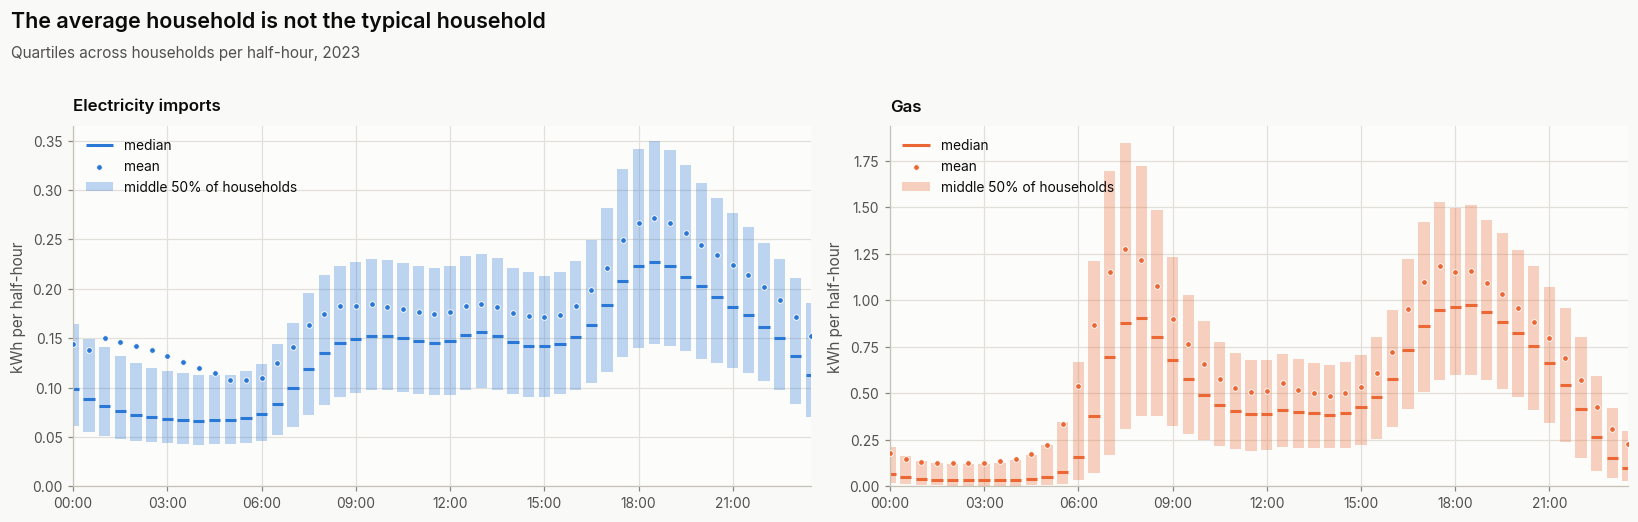

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, (q, color) in zip(axes, MAIN.items()):
    s = d23[d23["quantity"].eq(q)]
    x = s["half_hour"].to_numpy()
    ax.bar(x, (s["75th_percentile"] - s["25th_percentile"]) / 1000, bottom=s["25th_percentile"] / 1000, width=0.72,
           color=color, alpha=0.30, edgecolor="none", label="middle 50% of households")
    ax.hlines(s["median"] / 1000, x - 0.36, x + 0.36, color=color, lw=2, label="median")
    ax.scatter(x, s["mean"] / 1000, color=color, s=14, zorder=3, edgecolor=COLORS["surface"], linewidth=0.6,
               label="mean")
    plots.half_hour_axis(ax); ax.set_ylim(bottom=0); ax.set_ylabel("kWh per half-hour")
    ax.set_title(q, loc="left", fontsize=11); ax.legend(loc="upper left")
plots.figure_title(fig, "The average household is not the typical household",
                   "Quartiles across households per half-hour, 2023")
reporter.save_fig(fig, "quartiles-by-half-hour-2023")
plt.show()

## 5. How precise are the averages?

The evening (15:00–21:00) electricity profile of each year with its 95% confidence interval. With about 10,000 households per half-hour the intervals are narrow (about ±1.5%), so even small year-to-year changes in the profile are statistically clear.


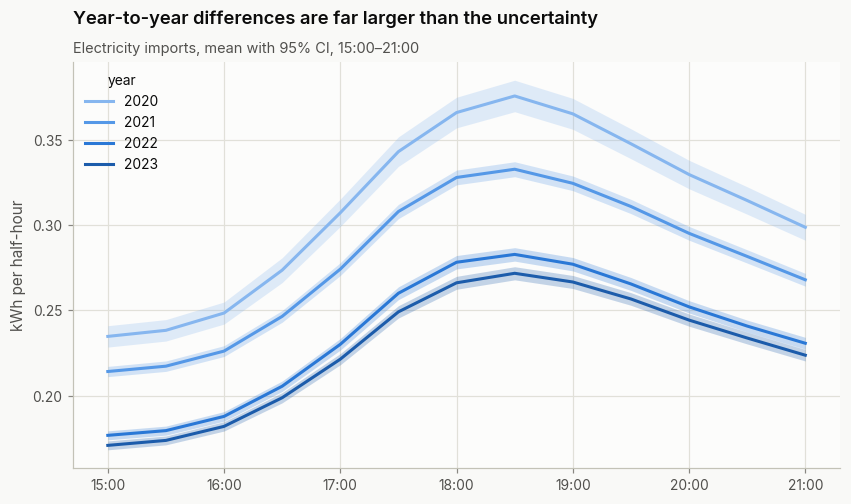

In [6]:
imp = base[base["quantity"].eq("Electricity imports") & base["half_hour"].between(30, 42)]
fig, ax = plt.subplots(figsize=(9, 4.8))
for y, s in imp.groupby("year"):
    ax.fill_between(s["half_hour"], s["ci95_low"] / 1000, s["ci95_high"] / 1000, color=YEAR_COLORS[y], alpha=0.25, lw=0)
    ax.plot(s["half_hour"], s["mean"] / 1000, color=YEAR_COLORS[y], label=str(y))
ax.set_xticks(range(30, 43, 2), [f"{h // 2:02d}:{30 * (h % 2):02d}" for h in range(30, 43, 2)])
ax.set_ylabel("kWh per half-hour"); ax.legend(title="year", loc="upper left")
plots.title(ax, "Year-to-year differences are far larger than the uncertainty",
            "Electricity imports, mean with 95% CI, 15:00–21:00")
reporter.save_fig(fig, "evening-peak-confidence-intervals")
plt.show()

## 6. Statistics at the two daily peaks (2023)

All derived statistics for the 18:30 electricity peak and the morning gas peak, the two half-hours that matter most for the networks.


In [7]:
row_e = d23[d23["quantity"].eq("Electricity imports") & d23["summary_time"].eq("18:30")].iloc[0]
row_g = d23[d23["quantity"].eq("Gas")].sort_values("mean").iloc[-1]
cols = ["n_rounded", "mean", "median", "25th_percentile", "75th_percentile", "standard_deviation",
        "standard_error_mean", "cv", "iqr", "bowley_skew", "pearson_skew", "ci95_low", "ci95_high", "n_from_sem"]
peaks = pd.DataFrame({f"electricity_{row_e['summary_time'].replace(':', '')}": row_e[cols],
                      f"gas_{row_g['summary_time'].replace(':', '')}": row_g[cols]})
peaks.index = ["households", "mean_wh", "median_wh", "q1_wh", "q3_wh", "sd_wh", "se_wh", "cv", "iqr_wh",
               "bowley_skew", "pearson_skew", "ci95_low_wh", "ci95_high_wh", "households_from_sem"]
peaks.index.name = "statistic"
print(peaks.astype(float).round(3).to_string())
reporter.save_table(peaks, "peak_half_hour_stats_2023", index=True)

                     electricity_1830  gas_0730
statistic                                      
households                   9080.000  7260.000
mean_wh                       271.761  1274.991
median_wh                     227.495   879.699
q1_wh                         144.220   310.524
q3_wh                         349.094  1844.114
sd_wh                         186.815  1304.761
se_wh                           1.961    15.313
cv                              0.687     1.023
iqr_wh                        204.874  1533.590
bowley_skew                     0.187     0.258
pearson_skew                    0.711     0.909
ci95_low_wh                   267.918  1244.977
ci95_high_wh                  275.604  1305.005
households_from_sem          9080.000  7260.000


## Conclusions

- **Households differ most at night.** The CV is about 0.7–0.9 during the day and well above 1 overnight: at night a minority (storage heaters, EV charging, night tariffs) uses far more than most.
- **The spread is lopsided at every hour** (positive skewness), so the mean overstates the typical household; medians are the better "typical" figure, means the right one for totals and network load.
- **The averages are precise:** with about 10,000 households per half-hour, 95% intervals are about ±1.5% of the mean, so the year-to-year fall in the evening peak is real, not noise.
- **SERL's numbers are internally consistent:** the household counts implied by sd / SEM match the published counts.

## Limitations

- Whole sample only: the spread *within* specific groups is not shown here.
- Quartiles and moments describe households' annual average day, not individual days, so day-to-day variation is not captured.
